# Otimização de CNN1D Quantizada para FPGA (ATLAS L0 Ringer)
## Alocação de Bits por Lagrange/KKT e Fronteira de Pareto Multi-Objetivo (NSGA-II)

Este notebook implementa a metodologia de codesign de rede neural compacta para o sistema de filtragem de elétrons do ATLAS L0 Ringer.

### Objetivos do Experimento:
1. **Redução Arquitetural**: Simplificar a CNN1D original de 2 convoluções e 2 densas para uma estrutura compacta viável em hardware FPGA;
2. **Quantização Heterogênea Ótima**: Determinar a precisão ótima de bits de cada camada via expansão de Taylor de 2ª ordem da perda $\Delta \mathcal{L}$, estimativa do traço da Hessiana via algoritmo de Hutchinson, e solução analítica das condições KKT (*water-filling*);
3. **Mapeamento de Hiperparâmetros Bi-Objetivo**: Gerar a **Fronteira de Pareto** ($\max SP$ vs. $\min \text{BOPs}$) via algoritmo genético NSGA-II e busca TPE com penalidade de hardware.


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
import qkeras
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc

# Adicionar raiz do repositório ao PYTHONPATH
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.metrics import compute_sp, norm1, SPCallback
from src.hardware import compute_model_hardware_costs
from src.kkt_allocator import (
    compute_hutchinson_hessian_trace,
    compute_layer_c_coefficients,
    solve_kkt_bit_allocation
)
from src.models import build_compact_cnn1d_fp32, build_compact_qcnn1d

print("TensorFlow Version:", tf.__version__)
print("QKeras Version:", qkeras.__version__)
print("Repository Root:", repo_root)


2026-11-07 00:30:33.743204: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-07 00:30:33.743514: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-07 00:30:33.774489: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-07 00:30:34.593537: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-07 00:30:34.593789: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.20.0
QKeras Version: 0.9.0
Repository Root: /home/iaraujo/Documentos/Github/cnn-optimization


## 1. Ingestão e Pré-processamento dos Dados Ringer

Os anéis de energia do calorímetro representam a deposição transversal em coordenadas concêntricas.
Aplicamos a normalização L1 por evento:

$$\hat{x}_i = \frac{x_i}{\sum_{j=1}^M |x_j|}$$

E fatiamos para a resolução reduzida $v_1$ (50 anéis).


In [2]:
# Parâmetros da Região do Detector
iet = 5
ieta = 0
data_path = os.path.join(repo_root, 'data', f'mc21_13p6TeV.Zee.JF17.2sigma.5M.et{iet}_eta{ieta}.h5')

if not os.path.exists(data_path):
    raise FileNotFoundError(f"Arquivo de dados não encontrado em: {data_path}")

print(f"Carregando dados de: {data_path}")
df_loaded = pd.read_hdf(data_path, key='data')

ring_columns = [col for col in df_loaded.columns if col.startswith('trig_L2_cl_ring_')]
ring_columns = sorted(ring_columns, key=lambda x: int(x.split('_')[-1]))

signal_df = df_loaded[df_loaded['target'] == 1][ring_columns]
background_df = df_loaded[df_loaded['target'] == 0][ring_columns]

ns = min(len(signal_df), len(background_df))
print(f"Total de amostras balanceadas: {ns*2} (Sinal: {ns}, Fundo: {ns})")

# Normalização de energia
sig_normed = norm1(signal_df.values[:ns])
bkg_normed = norm1(background_df.values[:ns])

# Versão v1: 50 anéis (fator de redução = 2 nas camadas do calorímetro)
ESTRUTURA_BASE = {"PS": 8, "EM1": 64, "EM2": 8, "EM3": 8, "HAD1": 4, "HAD2": 4, "HAD3": 4}
fator_reducao = 2
indices_v1 = []
ponteiro = 0
for camada, qtd in ESTRUTURA_BASE.items():
    indices_v1.extend(range(ponteiro, ponteiro + qtd // fator_reducao))
    ponteiro += qtd

X_v1 = np.vstack([sig_normed[:, indices_v1], bkg_normed[:, indices_v1]]).astype(np.float32)
y = np.vstack([np.ones((ns, 1)), np.zeros((ns, 1))]).ravel().astype(np.float32)

print(f"Shape final do dataset X_v1: {X_v1.shape}, Labels y: {y.shape}")


Carregando dados de: /home/iaraujo/Documentos/Github/cnn-optimization/data/mc21_13p6TeV.Zee.JF17.2sigma.5M.et5_eta0.h5


Total de amostras balanceadas: 77126 (Sinal: 38563, Fundo: 38563)
Shape final do dataset X_v1: (77126, 50), Labels y: (77126,)


## 2. Treinamento da CNN1D Compacta em FP32 (Baseline)

Treinamos uma CNN1D enxuta (1 camada de convolução com 8 filtros, MaxPooling e 1 camada densa de 8 neurônios) monitorando o **Índice Soma-Produto ($SP$)** na validação:

$$SP = \sqrt{\sqrt{PD \cdot (1 - FA)} \cdot \left[ \frac{PD + (1 - FA)}{2} \right]}$$


In [3]:
# Divisão estratificada Treino / Validação
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(skf.split(X_v1, y))

X_train, y_train = X_v1[train_idx], y[train_idx]
X_val, y_val = X_v1[val_idx], y[val_idx]

input_dim = X_v1.shape[1]
model_fp32 = build_compact_cnn1d_fp32(input_dim=input_dim, num_filters=8, kernel_size=3, dense_units=8)

sp_cb_fp32 = SPCallback(val_data=(X_val, y_val), patience=10, verbose=True)

history_fp32 = model_fp32.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=512,
    callbacks=[sp_cb_fp32],
    verbose=1
)

sp_cb_fp32.restore_best_weights()
hw_fp32 = compute_model_hardware_costs(model_fp32, input_dim=input_dim)

print(f"\n[Baseline FP32] Melhor SP: {sp_cb_fp32.best_sp:.4f} (PD: {sp_cb_fp32.best_pd_at_knee:.4f}, FA: {sp_cb_fp32.best_fa_at_knee:.4f})")
print(f"[Hardware Baseline] Total MACs: {hw_fp32['total_macs']}, Parâmetros: {hw_fp32['total_params']}")


Epoch 1/15


2026-11-07 00:30:35.751738: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


  1/121 [..............................] - ETA: 53s - loss: 0.6892 - accuracy: 0.6875

 31/121 [======>.......................] - ETA: 0s - loss: 0.6726 - accuracy: 0.8656 

 67/121 [===============>..............] - ETA: 0s - loss: 0.6457 - accuracy: 0.9057

 77/121 [==================>...........] - ETA: 0s - loss: 0.6362 - accuracy: 0.9128

... (85 outputs left out)

 73/121 [=================>............] - ETA: 0s - loss: 0.0370 - accuracy: 0.9875

107/121 [=========================>....] - ETA: 0s - loss: 0.0364 - accuracy: 0.9878


[SPCallback] Epoch 15: New best SP = 0.9877 (PD=0.9922, FA=0.0169)
121/121 [==============================] - 0s 2ms/step - loss: 0.0368 - accuracy: 0.9877 - val_loss: 0.0401 - val_accuracy: 0.9876 - val_sp: 0.9877 - val_pd_knee: 0.9922 - val_fa_knee: 0.0169



[Baseline FP32] Melhor SP: 0.9877 (PD: 0.9922, FA: 0.0169)
[Hardware Baseline] Total MACs: 2808, Parâmetros: 1649


## 3. Alocação Ótima de Bits por Multiplicadores de Lagrange e Condições KKT

A perda esperada sob quantização de pesos com ruído $\sigma_i^2 \propto 4^{-b_i}$ é:

$$\min_{\mathbf{b}} \sum_{i=1}^L c_i 4^{-b_i} \quad \text{s.a.} \quad \sum_{i=1}^L a_i b_i \le B, \quad b_{\min} \le b_i \le b_{\max}$$

onde:
- $c_i = \operatorname{Tr}(\mathbf{H}_i) \frac{n_i r_i^2}{3}$ é o fator de sensibilidade intrínseca da camada $i$;
- $a_i = \text{MAC}_i \cdot b_{a,i}$ é o custo em hardware por bit;
- A solução analítica KKT (*water-filling*) é dada por:

$$b_i^*(\lambda) = \min\left( b_{\max}, \max\left( b_{\min}, \frac{1}{2} \log_2 \left( \frac{c_i \ln 4}{\lambda a_i} \right) \right) \right)$$


In [4]:
# 1. Estimativa do Traço da Hessiana via Algoritmo de Hutchinson (Monte Carlo com Rademacher)
sample_idx = np.random.choice(len(X_val), size=512, replace=False)
x_sample_tf = tf.convert_to_tensor(X_val[sample_idx])
y_sample_tf = tf.convert_to_tensor(y_val[sample_idx], dtype=tf.float32)[:, None]
bce_loss = keras.losses.BinaryCrossentropy()

print("Calculando traço da Hessiana Tr(H_i) via produtos Hessiana-vetor...")
traces = compute_hutchinson_hessian_trace(model_fp32, bce_loss, x_sample_tf, y_sample_tf, num_hvp=10)
c_coeffs = compute_layer_c_coefficients(model_fp32, traces)

# 2. Extração dos custos de hardware a_i = MACs_i * b_a,i
layer_names = [item['layer_name'] for item in hw_fp32['breakdown']]
a_costs = [item['macs'] * item['b_a'] for item in hw_fp32['breakdown']]
c_list = [c_coeffs[name] for name in layer_names]

# 3. Definição de Orçamentos de Hardware (BOPs)
# 8 bits uniforme equivale ao orçamento máximo
bops_uniform_8bit = sum(a * 8 for a in a_costs)
budget_target = bops_uniform_8bit * 0.60  # Redução de 40% no consumo de BOPs

kkt_result = solve_kkt_bit_allocation(
    layer_names=layer_names,
    c_coeffs=c_list,
    a_costs=a_costs,
    budget_bops=budget_target,
    b_min=2,
    b_max=8
)

print(f"\nOrçamento Máximo (8-bit uniforme): {bops_uniform_8bit:,.0f} BOPs")
print(f"Orçamento Alvo (60%): {budget_target:,.0f} BOPs")
print(f"Preço-Sombra Ótimo (λ*): {kkt_result['lambda_optimal']:.6e}")
print("\n=== Alocação Ótima de Bits por Camada (KKT) ===")
for name in layer_names:
    b_cont = kkt_result['continuous_bits'][name]
    b_int = kkt_result['integer_bits'][name]
    print(f"• {name:15s} | Tr(H): {traces[name]:.4e} | Custo a_i: {a_costs[layer_names.index(name)]:6.0f} | Bits Contínuos: {b_cont:.2f} | Bits Inteiros: {b_int}b")

print(f"\nBOPs Realizados pelo Modelo KKT: {kkt_result['achieved_bops']:,.0f} ({kkt_result['achieved_bops']/bops_uniform_8bit*100:.1f}% do 8-bit)")


Calculando traço da Hessiana Tr(H_i) via produtos Hessiana-vetor...



Orçamento Máximo (8-bit uniforme): 179,712 BOPs
Orçamento Alvo (60%): 107,827 BOPs
Preço-Sombra Ótimo (λ*): 1.481692e-06

=== Alocação Ótima de Bits por Camada (KKT) ===
• conv1d_1        | Tr(H): 3.3351e-02 | Custo a_i:   9600 | Bits Contínuos: 2.42 | Bits Inteiros: 3b
• dense_1         | Tr(H): 3.2107e-01 | Custo a_i:  12800 | Bits Contínuos: 6.60 | Bits Inteiros: 6b
• output_dense    | Tr(H): 1.0000e-08 | Custo a_i:     64 | Bits Contínuos: 2.00 | Bits Inteiros: 8b

BOPs Realizados pelo Modelo KKT: 106,112 (59.0% do 8-bit)


## 4. Treinamento da CNN1D Quantizada com Precisão Mista (KKT QAT)

Instanciamos o modelo QKeras com a alocação de bits determinada matematicamente por KKT e executamos o treinamento ciente de quantização (*Quantization-Aware Training* - QAT).


In [5]:
kkt_weights_bits = kkt_result['integer_bits']

# Modelo QKeras com alocação KKT
model_qkeras_kkt = build_compact_qcnn1d(
    input_dim=input_dim,
    num_filters=8,
    kernel_size=3,
    dense_units=8,
    weights_bits=kkt_weights_bits,
    act_bits=8
)

sp_cb_qkeras = SPCallback(val_data=(X_val, y_val), patience=10, verbose=True)

history_qkeras = model_qkeras_kkt.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=512,
    callbacks=[sp_cb_qkeras],
    verbose=1
)

sp_cb_qkeras.restore_best_weights()
hw_qkeras_kkt = compute_model_hardware_costs(model_qkeras_kkt, weights_bits=kkt_weights_bits, input_dim=input_dim)

print(f"\n[QKeras KKT Mixed-Precision] Melhor SP: {sp_cb_qkeras.best_sp:.4f} (PD: {sp_cb_qkeras.best_pd_at_knee:.4f}, FA: {sp_cb_qkeras.best_fa_at_knee:.4f})")
print(f"[Hardware KKT] Total BOPs: {hw_qkeras_kkt['total_bops']:,} | Parâmetros: {hw_qkeras_kkt['total_params']}")


Epoch 1/15


  1/121 [..............................] - ETA: 59s - loss: 0.6990 - accuracy: 0.4961

 21/121 [====>.........................] - ETA: 0s - loss: 0.6658 - accuracy: 0.7325 

 38/121 [========>.....................] - ETA: 0s - loss: 0.6383 - accuracy: 0.8139

 50/121 [===========>..................] - ETA: 0s - loss: 0.6220 - accuracy: 0.8439

 71/121 [================>.............] - ETA: 0s - loss: 0.5973 - accuracy: 0.8780

... (114 outputs left out)

 98/121 [=======================>......] - ETA: 0s - loss: 0.6938 - accuracy: 0.4978

115/121 [===========================>..] - ETA: 0s - loss: 0.6937 - accuracy: 0.4980


[SPCallback] Early stopping at epoch 13. Best SP was 0.9863 at epoch 3.
121/121 [==============================] - 1s 5ms/step - loss: 0.6938 - accuracy: 0.4977 - val_loss: 0.6937 - val_accuracy: 0.5000 - val_sp: 0.0897 - val_pd_knee: 1.0000 - val_fa_knee: 0.9997



[QKeras KKT Mixed-Precision] Melhor SP: 0.9863 (PD: 0.9931, FA: 0.0205)
[Hardware KKT] Total BOPs: 106,112 | Parâmetros: 1649


## 5. Otimização Bi-Objetivo e Fronteira de Pareto (NSGA-II)

Avaliamos simultaneamente os dois objetivos conflitantes do trigger:

$$\max f_1(\boldsymbol{\theta}) = SP_{\text{val}}(\boldsymbol{\theta})$$

$$\min f_2(\boldsymbol{\theta}) = \text{BOPs}(\boldsymbol{\theta})$$

Utilizamos o algoritmo **NSGA-II** (*Non-dominated Sorting Genetic Algorithm II*) via Optuna para encontrar a curva de *trade-off* exata da arquitetura.


In [6]:
import optuna

def objective(trial):
    n_filters = trial.suggest_categorical("filters", [4, 8, 16])
    k_size = trial.suggest_categorical("kernel_size", [3, 5])
    d_units = trial.suggest_categorical("dense_units", [4, 8])
    b_conv = trial.suggest_categorical("b_conv", [4, 6, 8])
    b_dense = trial.suggest_categorical("b_dense", [4, 6, 8])
    lr = trial.suggest_float("lr", 1e-3, 5e-3, log=True)

    weights_bits = {
        "conv1d_1": b_conv,
        "dense_1": b_dense,
        "output_dense": 8
    }

    model_trial = build_compact_qcnn1d(
        input_dim=input_dim,
        num_filters=n_filters,
        kernel_size=k_size,
        dense_units=d_units,
        weights_bits=weights_bits,
        act_bits=8,
        learning_rate=lr
    )

    costs = compute_model_hardware_costs(model_trial, weights_bits=weights_bits, input_dim=input_dim)
    bops = float(costs["total_bops"])

    # Treino rápido de avaliação (5 épocas)
    sp_cb_trial = SPCallback(val_data=(X_val, y_val), patience=4, verbose=False)
    model_trial.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=5,
        batch_size=1024,
        callbacks=[sp_cb_trial],
        verbose=0
    )

    sp_val = float(sp_cb_trial.best_sp)
    return sp_val, bops

study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=optuna.samplers.NSGAIISampler(seed=42)
)

print("Iniciando busca bi-objetivo com NSGA-II (10 trials para demonstração)...")
study.optimize(objective, n_trials=10)

print("\n=== Soluções na Fronteira de Pareto ===")
pareto_trials = study.best_trials
for t in pareto_trials:
    print(f"Trial #{t.number}: SP = {t.values[0]:.4f} | BOPs = {t.values[1]:,.0f} | Params: {t.params}")


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-07 00:30:48,767] A new study created in memory with name: no-name-985a4384-5a2b-42e1-90d5-d6cd43a6b3c6


Iniciando busca bi-objetivo com NSGA-II (10 trials para demonstração)...


[I 2026-11-07 00:30:51,924] Trial 0 finished with values: [0.9838417356323764, 77056.0] and parameters: {'filters': 8, 'kernel_size': 3, 'dense_units': 4, 'b_conv': 4, 'b_dense': 6, 'lr': 0.0014074036373847476}.


[I 2026-11-07 00:30:56,777] Trial 1 finished with values: [0.9864447987561785, 307712.0] and parameters: {'filters': 16, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 8, 'b_dense': 6, 'lr': 0.002287886352244589}.


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


[I 2026-11-07 00:31:01,239] Trial 2 finished with values: [0.9846994468311703, 179712.0] and parameters: {'filters': 16, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 4, 'b_dense': 4, 'lr': 0.002218777775048716}.


... (8 outputs left out)

/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


[I 2026-11-07 00:31:26,014] Trial 8 finished with values: [0.9846217220216582, 64512.0] and parameters: {'filters': 4, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 8, 'b_dense': 4, 'lr': 0.0019885455014678173}.


[I 2026-11-07 00:31:30,972] Trial 9 finished with values: [0.9863822573558949, 96256.0] and parameters: {'filters': 8, 'kernel_size': 3, 'dense_units': 4, 'b_conv': 6, 'b_dense': 6, 'lr': 0.0047780041934215095}.



=== Soluções na Fronteira de Pareto ===
Trial #4: SP = 0.9867 | BOPs = 205,312 | Params: {'filters': 8, 'kernel_size': 5, 'dense_units': 8, 'b_conv': 8, 'b_dense': 6, 'lr': 0.004895582417605464}
Trial #5: SP = 0.9808 | BOPs = 54,912 | Params: {'filters': 4, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 6, 'b_dense': 4, 'lr': 0.0011077082247709848}
Trial #8: SP = 0.9846 | BOPs = 64,512 | Params: {'filters': 4, 'kernel_size': 3, 'dense_units': 8, 'b_conv': 8, 'b_dense': 4, 'lr': 0.0019885455014678173}
Trial #9: SP = 0.9864 | BOPs = 96,256 | Params: {'filters': 8, 'kernel_size': 3, 'dense_units': 4, 'b_conv': 6, 'b_dense': 6, 'lr': 0.0047780041934215095}


## 6. Curvas ROC e Fronteira de Pareto Visual para o Artigo

Geramos as curvas de desempenho para comparação direta e publicação.


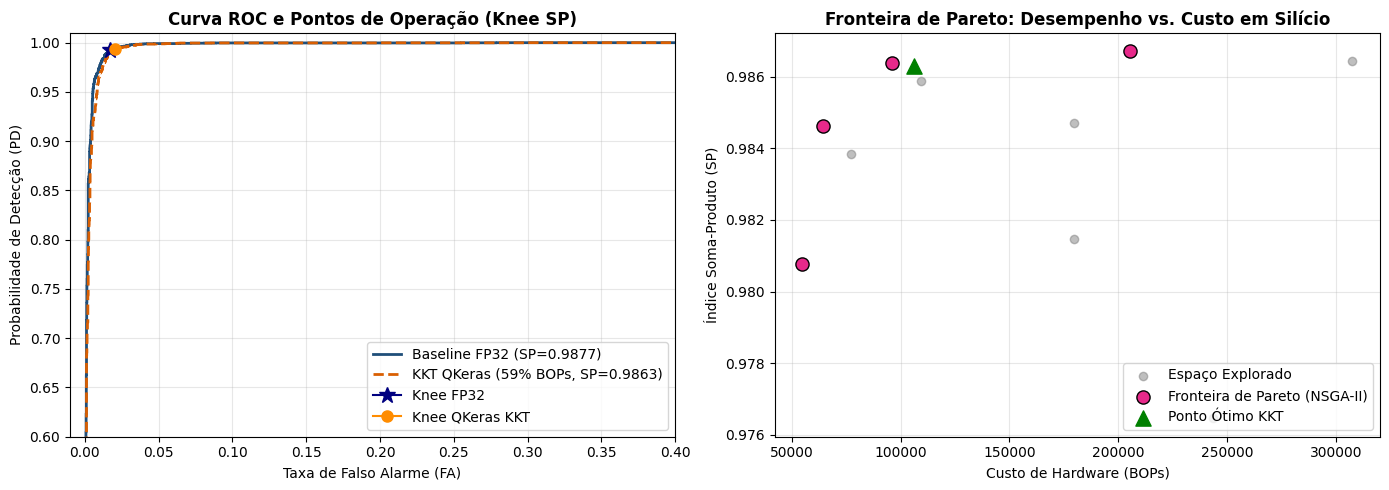

Gráficos salvos com sucesso em: /home/iaraujo/Documentos/Github/cnn-optimization/docs/plots/comparativo_roc_pareto.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Curvas ROC Sobrepostas
y_pred_fp32 = model_fp32.predict(X_val, batch_size=2048, verbose=0).ravel()
y_pred_qkeras = model_qkeras_kkt.predict(X_val, batch_size=2048, verbose=0).ravel()

fa_fp32, pd_fp32, _ = roc_curve(y_val, y_pred_fp32)
fa_q, pd_q, _ = roc_curve(y_val, y_pred_qkeras)

axes[0].plot(fa_fp32, pd_fp32, label=f'Baseline FP32 (SP={sp_cb_fp32.best_sp:.4f})', color='#1f4e79', lw=2)
axes[0].plot(fa_q, pd_q, label=f'KKT QKeras ({kkt_result["achieved_bops"]/bops_uniform_8bit*100:.0f}% BOPs, SP={sp_cb_qkeras.best_sp:.4f})', color='#d95f02', lw=2, linestyle='--')
axes[0].plot([sp_cb_fp32.best_fa_at_knee], [sp_cb_fp32.best_pd_at_knee], marker='*', markersize=12, color='navy', label='Knee FP32')
axes[0].plot([sp_cb_qkeras.best_fa_at_knee], [sp_cb_qkeras.best_pd_at_knee], marker='o', markersize=8, color='darkorange', label='Knee QKeras KKT')

axes[0].set_title("Curva ROC e Pontos de Operação (Knee SP)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Taxa de Falso Alarme (FA)")
axes[0].set_ylabel("Probabilidade de Detecção (PD)")
axes[0].set_xlim(-0.01, 0.4)
axes[0].set_ylim(0.6, 1.01)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower right')

# 2. Fronteira de Pareto: SP vs. BOPs
all_sp = [t.values[0] for t in study.trials if t.values is not None]
all_bops = [t.values[1] for t in study.trials if t.values is not None]
pareto_sp = [t.values[0] for t in pareto_trials]
pareto_bops = [t.values[1] for t in pareto_trials]

axes[1].scatter(all_bops, all_sp, color='gray', alpha=0.5, label='Espaço Explorado')
axes[1].scatter(pareto_bops, pareto_sp, color='#e7298a', s=90, edgecolor='black', label='Fronteira de Pareto (NSGA-II)')
axes[1].scatter([hw_qkeras_kkt['total_bops']], [sp_cb_qkeras.best_sp], color='green', marker='^', s=120, label='Ponto Ótimo KKT')

axes[1].set_title("Fronteira de Pareto: Desempenho vs. Custo em Silício", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Custo de Hardware (BOPs)")
axes[1].set_ylabel("Índice Soma-Produto (SP)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='lower right')

plt.tight_layout()
plots_dir = os.path.join(repo_root, 'docs', 'plots')
os.makedirs(plots_dir, exist_ok=True)
plot_save_path = os.path.join(plots_dir, 'comparativo_roc_pareto.png')
plt.savefig(plot_save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráficos salvos com sucesso em: {plot_save_path}")


## 7. Tabela Síntese para Escrita de Artigo

Tabela comparativa consolidada com métricas de física ($SP, PD, FA$) e métricas de síntese de hardware ($\text{MACs}, \text{BOPs}, \text{Bits de Pesos}$).


In [8]:
summary_data = [
    {
        "Modelo": "Baseline FP32 Compacto",
        "Precisão": "Float32",
        "SP Max": f"{sp_cb_fp32.best_sp:.4f}",
        "PD Knee": f"{sp_cb_fp32.best_pd_at_knee:.4f}",
        "FA Knee": f"{sp_cb_fp32.best_fa_at_knee:.4f}",
        "MACs": f"{hw_fp32['total_macs']:,}",
        "BOPs": f"{hw_fp32['total_bops']:,}",
        "Bits Pesos": f"{hw_fp32['total_weight_bits']:,}"
    },
    {
        "Modelo": "QKeras KKT Heterogêneo",
        "Precisão": f"Conv: {kkt_weights_bits['conv1d_1']}b | Dense: {kkt_weights_bits['dense_1']}b | Out: {kkt_weights_bits['output_dense']}b",
        "SP Max": f"{sp_cb_qkeras.best_sp:.4f}",
        "PD Knee": f"{sp_cb_qkeras.best_pd_at_knee:.4f}",
        "FA Knee": f"{sp_cb_qkeras.best_fa_at_knee:.4f}",
        "MACs": f"{hw_qkeras_kkt['total_macs']:,}",
        "BOPs": f"{hw_qkeras_kkt['total_bops']:,}",
        "Bits Pesos": f"{hw_qkeras_kkt['total_weight_bits']:,}"
    }
]

df_summary = pd.DataFrame(summary_data)
display(df_summary)


,Modelo,Precisão,SP Max,PD Knee,FA Knee,MACs,BOPs,Bits Pesos
0,Baseline FP32 Compacto,Float32,0.9877,0.9922,0.0169,"2,808","179,712","13,192"
1,QKeras KKT Heterogêneo,Conv: 3b | Dense: 6b | Out: 8b,0.9863,0.9931,0.0205,"2,808","106,112","9,816"
